**Implementation for Zomato Data Analysis using Python**

***Step 1: Importing necessary Python libraries.***

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

***Step 2:Creating the data from***

In [2]:
df = pd.read_csv("Data/Zomato-data-.csv")

In [3]:
df.head()

,name,online_order,book_table,rate,votes,approx_cost(for two people),listed_in(type)
0,Jalsa,Yes,Yes,4.1/5,775,800,Buffet
1,Spice Elephant,Yes,No,4.1/5,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8/5,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7/5,88,300,Buffet
4,Grand Village,No,No,3.8/5,166,600,Buffet


***Step 3: Data Cleaning and Preparation***

In [4]:
def handleRate(value):
    value = str(value).split('/')
    value = value[0]
    return float(value)

df['rate'] = df['rate'].apply(handleRate)
print(df.head())

                    name online_order book_table  rate  votes  \
0                  Jalsa          Yes        Yes   4.1    775   
1         Spice Elephant          Yes         No   4.1    787   
2        San Churro Cafe          Yes         No   3.8    918   
3  Addhuri Udupi Bhojana           No         No   3.7     88   
4          Grand Village           No         No   3.8    166   

   approx_cost(for two people) listed_in(type)  
0                          800          Buffet  
1                          800          Buffet  
2                          800          Buffet  
3                          300          Buffet  
4                          600          Buffet  


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   name                         148 non-null    object 
 1   online_order                 148 non-null    object 
 2   book_table                   148 non-null    object 
 3   rate                         148 non-null    float64
 4   votes                        148 non-null    int64  
 5   approx_cost(for two people)  148 non-null    int64  
 6   listed_in(type)              148 non-null    object 
dtypes: float64(1), int64(2), object(4)
memory usage: 8.2+ KB


In [6]:
df.isnull().sum()

name                           0
online_order                   0
book_table                     0
rate                           0
votes                          0
approx_cost(for two people)    0
listed_in(type)                0
dtype: int64

No NULL value

**Step 4: Exploring Restaurant Types**

Text(0.5, 0, 'Types of the Resturent')

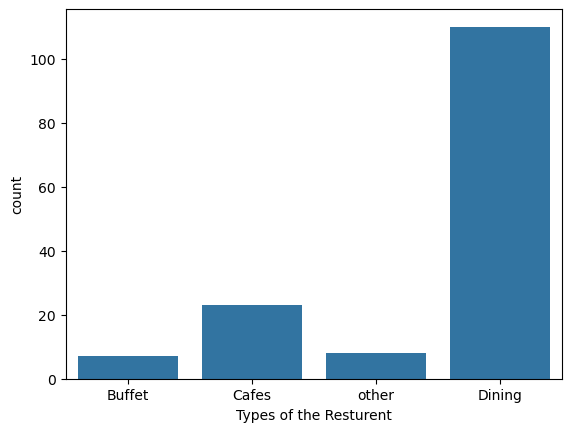

In [7]:
sns.countplot(x = df['listed_in(type)'])
plt.xlabel('Types of the Resturent')

***Conclusion: The majority of the restaurants fall into the dining category.***

Text(0, 0.5, 'Votes')

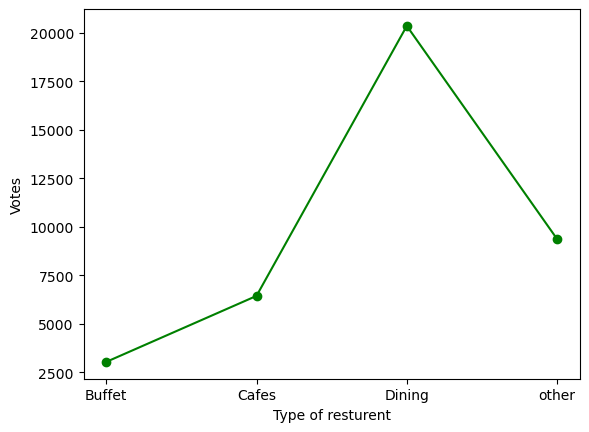

In [8]:
grouped_data = df.groupby('listed_in(type)')['votes'].sum()
result = pd.DataFrame({'votes':grouped_data})
plt.plot(result, c='green', marker = 'o')
plt.xlabel('Type of resturent')
plt.ylabel('Votes')

***Conclusion: Dining restaurants are preferred by a larger number of individuals.***

***Step 5: Identify the Most Voted Restaurant***

In [10]:
max_votes = df['votes'].max()
resturent_with_max_votes = df.loc[df['votes'] == max_votes, 'name']

print("Resturent with the maximum votes")
print(resturent_with_max_votes)

Resturent with the maximum votes
38    Empire Restaurant
Name: name, dtype: object


***Step 6: Online Order Availability***

<Axes: xlabel='online_order', ylabel='count'>

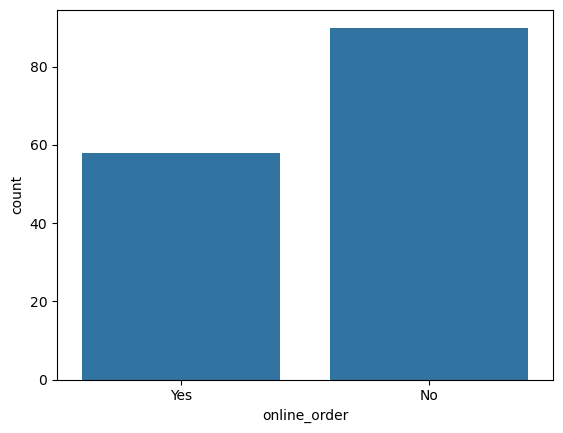

In [11]:
sns.countplot(x = df['online_order'])

***Conclusion: This suggests that a majority of the restaurants do not accept online orders.***

***Step 7: Analyze Ratings***

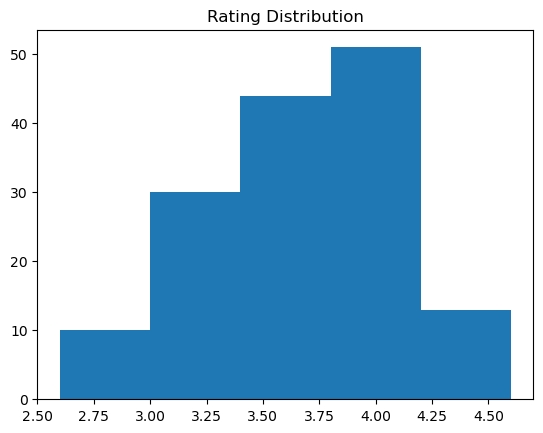

In [16]:
plt.hist(df['rate'],bins = 5)
plt.title("Rating Distribution")
plt.show()

***Conclusion: The majority of restaurants received ratings ranging from 3.5 to 4.***

***Step 8: Approximate Cost for Couples***

<Axes: xlabel='approx_cost(for two people)', ylabel='count'>

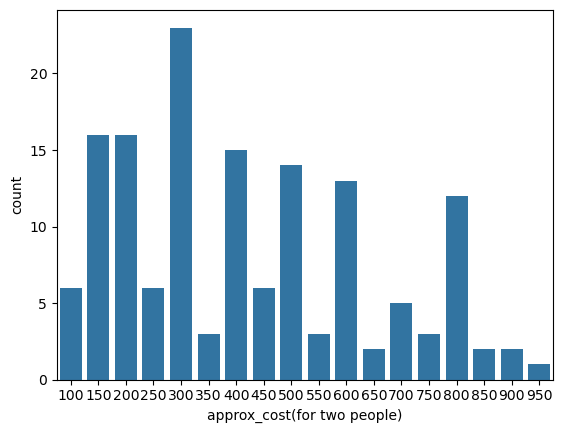

In [24]:
couple = df['approx_cost(for two people)']
sns.countplot(x=couple)

***Conclusion: The majority of couples prefer restaurants with an approximate cost of 300 rupees.***

**Step 9: Ratings Comparison - Online vs Offline Orders**

<Axes: xlabel='online_order', ylabel='rate'>

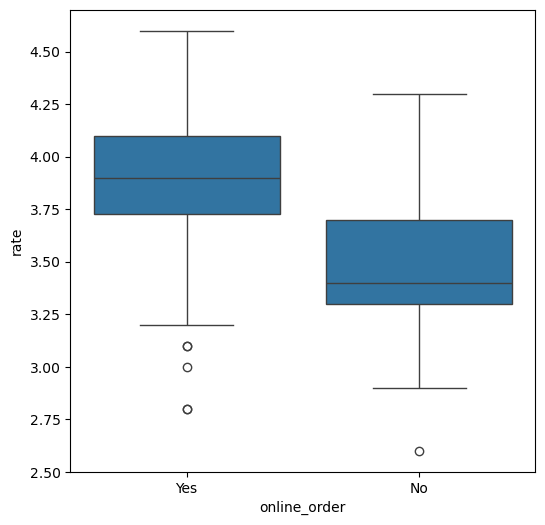

In [27]:
plt.figure(figsize=(6,6))
sns.boxplot(x= 'online_order', y='rate', data = df)

***Conclusion: Offline orders received lower ratings in comparison to online orders which obtained excellent ratings***

**Step 10: Order Mode Preferences by Restaurant Type**

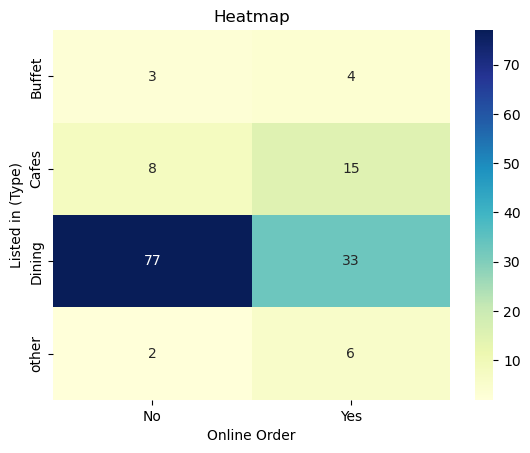

In [32]:
pivot_table = df.pivot_table(index = 'listed_in(type)', columns='online_order', 
                             aggfunc ='size' , fill_value=0)
sns.heatmap(pivot_table, annot = True, cmap='YlGnBu', fmt = 'd')
plt.title('Heatmap')
plt.xlabel('Online Order')
plt.ylabel('Listed in (Type)')
plt.show()

With this we can say that dining restaurants primarily accept offline orders whereas cafes primarily receive online orders. This suggests that clients prefer to place orders in person at restaurants but prefer online ordering at cafes.